# Auswertung von Wiederanstiegsversuchen nach Theis

**Hydraulische Methoden · Hydrogeologie · Karlsruher Institut für Technologie (KIT)**

Dieses Notebook behandelt die **Auswertung des Wiederanstiegs nach dem Abschalten einer Pumpe** mit dem Superpositionsprinzip und der **geradlinigen Theis-Wiederanstiegsmethode**.

**Lernziele:**

- den Unterschied zwischen Wiederanstieg und **verbleibender Absenkung** verstehen;
- die Zeitgrößen **t**, **t′** und **tₚ** richtig zuordnen;
- die Wiederanstiegsgleichung halblogarithmisch auswerten;
- die **Transmissivität T** aus der Geradensteigung bestimmen und die Anpassung beurteilen.

**Benötigte Pakete:** `numpy` und `matplotlib`. Alle Eingabedaten stehen in eigenen Codezellen und können für andere Pumpversuche ersetzt werden.

## 1. Theoretische Grundlagen

### 1.1 Absenkung, Wiederanstieg und verbleibende Absenkung

Während des Pumpens sinkt der Grundwasserstand ab. Nach dem Abschalten der Pumpe steigt er wieder an. Für die Auswertung betrachten wir die **verbleibende Absenkung sᵣ**: die Differenz zwischen dem **ursprünglichen Ruhewasserspiegel** und dem zu einem bestimmten Zeitpunkt **nach dem Pumpstopp** gemessenen Wasserstand. Beim Wiederanstieg nimmt **sᵣ** ab und nähert sich idealerweise null.

**Zeitdefinitionen:**

- **tₚ**: Pumpdauer bis zum Abschalten [s]
- **t′**: seit dem Abschalten vergangene Zeit [s]
- **t = tₚ + t′**: Zeit seit dem ursprünglichen Pumpbeginn [s]

Wichtig: In der Wiederanstiegsgleichung ist **t** nicht einfach die Pumpdauer **tₚ**.

### 1.2 Superpositionsprinzip

Ein Pumpstopp kann mathematisch als Überlagerung der ursprünglichen Entnahme mit einer **fiktiven Einspeisung gleicher Rate** ab dem Abschaltzeitpunkt beschrieben werden. Aus dieser Überlagerung ergibt sich unter Verwendung der logarithmischen Näherung die Geradlinienmethode für den Wiederanstieg. Eine vollständige Auswertung der Theis-Brunnenfunktion ist dafür nicht erforderlich.

**Modellannahmen:** gespannter, homogener und hinreichend ausgedehnter Grundwasserleiter; konstante Förderrate **Q** bis zum Abschalten; näherungsweise radialsymmetrische Strömung; unveränderte Aquiferparameter; vernachlässigbare zusätzliche Einflüsse (z. B. Brunnenverluste, Aquifergrenzen und Brunnenpeicherung).

### 1.3 Geradlinige Wiederanstiegsauswertung

Für hinreichend späte Zeiten kann die **verbleibende Absenkung sᵣ** näherungsweise durch

$$
\boxed{s_r\approx\frac{Q}{4\pi T}\ln\!\left(\frac{t}{t'}\right)
=\frac{Q\ln(10)}{4\pi T}\log_{10}\!\left(\frac{t}{t'}\right)}
$$

beschrieben werden. Dabei ist **Q** die Entnahmerate [m³/s] und **T** die Transmissivität [m²/s].

Trägt man **sᵣ** linear gegen das **Zeitverhältnis t/t′** auf logarithmischer Achse auf, ergibt sich idealerweise eine Gerade. Für die Steigung **m** pro logarithmischer Dekade gilt:

$$
\boxed{m=\frac{Q\ln(10)}{4\pi T},\qquad T=\frac{Q\ln(10)}{4\pi m}}.
$$

Die angepasste Gerade kann als **sᵣ = m · log₁₀(t/t′) + b** geschrieben werden. Unter idealen Bedingungen ist **b = 0**; bei Messdaten kann der Achsenabschnitt davon abweichen. Wir schätzen **b** zusammen mit **m**, um mögliche Abweichungen sichtbar zu machen. Ein von null abweichendes **b** belegt für sich allein keine bestimmte Randbedingung.

**Gültigkeit:** Die logarithmische Näherung gilt bei hinreichend kleinen dimensionslosen Theis-Zeitparametern **u** und **u′** (siehe Theis/Cooper-Jacob). Gerade frühe Wiederanstiegsdaten können die Näherung verletzen. In realen Pumpversuchen ist der Speicherkoeffizient **S** häufig unbekannt, sodass sich diese Voraussetzung nicht direkt prüfen lässt.

**Wichtig:** **S** kommt in dieser Wiederanstiegsgleichung nicht vor. Daher lässt sich die **Transmissivität T**, aber der **Speicherkoeffizient S nicht unabhängig** bestimmen.

## 2. Funktionen und Darstellungseinstellungen

Für die Geradlinienanpassung verwenden wir `numpy.polyfit` und kontrollieren das Ergebnis zusätzlich mit `numpy.linalg.lstsq`. Der **RMSE** ist die Wurzel aus dem *Mittelwert* der quadrierten Residuen und hat die Einheit Meter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Beschriftungen und Ausgaben
labels = {'lin_syn_title': 'Synthetischer Wiederanstieg – Messwerte', 'lin_real_title': 'Übungsaufgabe – beobachtete verbleibende Absenkung', 'tprime': 'Zeit seit Pumpstopp t′ [s]', 'residual': 'verbleibende Absenkung sᵣ [m]', 'measure': 'Messwerte', 'fittitle_syn': 'Synthetischer Wiederanstieg – Geradlinienauswertung', 'fittitle_real': 'Übungsaufgabe – Geradlinienauswertung', 'fit': 'Ausgleichsgerade (Regression)', 'ratio': 'Zeitverhältnis t/t′ [–] (logarithmisch)', 'intercept': 'Extrapolierter Nullschnittpunkt', 'restitle': 'Residuen der Wiederanstiegsgeraden', 'restxt': 'Residuum [m]', 'time': 'Zeit seit Pumpstopp t′ [s]', 'linezero': 'Nulllinie', 'pumped': 'Pumpe abgeschaltet nach', 'synthetic': 'Synthetischer Wiederanstiegsversuch', 'exercise': 'Übungsaufgabe', 'observations': 'Messpunkte', 'slope': 'Steigung m', 'axis': 'Achsenabschnitt b', 'trans': 'Transmissivität T', 'rmse': 'RMSE', 'interceptr': 'Nullschnittpunkt bei t/t′', 't_true': 'Vorgegebene Transmissivität T', 'reldiff': 'Abweichung gegenüber Vorgabe', 'duration': 'Aus den Zeitangaben ermittelte Pumpdauer tₚ', 'consistency': 'Zeitangaben nicht konsistent: t − t′ muss konstant und positiv sein.', 'crosscheck': 'Kontrolle mit numpy.linalg.lstsq', 'difference': 'Unterschied in T gegenüber numpy.polyfit', 'note_x': 'Das Zeitverhältnis muss größer als 1 sein.', 'nonpositive': 'Alle Parameter und Zeiten müssen positiv sein.', 'count': 'Zeit- und Messwertarrays müssen die gleiche Länge haben (mindestens zwei Punkte).', 'help': 'Die verwendeten Messwerte sind verbleibende Absenkungen, nicht der Betrag des Wasserstandsanstiegs.', 'outside': '(formale Extrapolation außerhalb des möglichen Bereichs t/t′ > 1)'}

plt.rcParams.update({
    "figure.figsize": (9, 5.3),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})


def recovery_straight_line(t_prime, t_p, Q, s_r):
    """Free-intercept OLS fit of residual drawdown against log10(t/t')."""
    t_prime = np.asarray(t_prime, dtype=float)
    s_r = np.asarray(s_r, dtype=float)
    if t_prime.ndim != 1 or s_r.ndim != 1 or len(t_prime) != len(s_r) or len(t_prime) < 2:
        raise ValueError(labels['count'])
    if t_p <= 0 or Q <= 0 or np.any(t_prime <= 0):
        raise ValueError(labels['nonpositive'])
    if not (np.all(np.isfinite(s_r)) and np.all(np.isfinite(t_prime))):
        raise ValueError('Non-finite values in data')
    ratio = (t_p + t_prime) / t_prime
    if np.any(ratio <= 1):
        raise ValueError(labels['note_x'])
    x = np.log10(ratio)
    m, b = np.polyfit(x, s_r, deg=1)
    if m <= 0:
        raise ValueError('Regression slope m must be positive')
    s_fit = m * x + b
    rmse = np.sqrt(np.mean((s_r - s_fit)**2))
    T_est = Q * np.log(10) / (4 * np.pi * m)
    return {'slope': m, 'intercept': b, 'transmissivity': T_est,
            'rmse': rmse, 's_fit': s_fit, 'ratio': ratio, 'log_ratio': x,
            'x0': 10**(-b/m)}


def print_results(title, result):
    print(title)
    print(f"  {labels['slope']} = {result['slope']:.5f} m/decade")
    print(f"  {labels['axis']} = {result['intercept']:.5f} m")
    print(f"  {labels['trans']} = {result['transmissivity']:.5e} m²/s")
    print(f"  {labels['rmse']} = {result['rmse']:.5f} m")
    intercept_note = ' ' + labels['outside'] if result['x0'] <= 1 else ''
    print(f"  {labels['interceptr']} = {result['x0']:.3f}{intercept_note}")


def plot_linear(t_prime, s_r, title):
    fig, ax = plt.subplots()
    ax.scatter(t_prime, s_r, s=45, color='C0', label=labels['measure'], zorder=3)
    ax.set(xlabel=labels['tprime'], ylabel=labels['residual'], title=title)
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_recovery_fit(t_prime, s_r, result, title):
    ratio = result['ratio']
    left = 1.0
    right = max(float(np.max(ratio)), float(result['x0'])) * 1.16
    xline = np.geomspace(left, right, 250)
    fig, ax = plt.subplots()
    ax.scatter(ratio, s_r, s=46, color='C0', zorder=3, label=labels['measure'])
    yline = result['slope'] * np.log10(xline) + result['intercept']
    ax.plot(xline, np.where(yline >= 0, yline, np.nan),
            color='C1', lw=2, label=labels['fit'])
    ax.axhline(0, color='0.5', lw=0.8, ls=':')
    if 1 <= result['x0'] <= right:
        ax.plot(result['x0'], 0, 'x', ms=11, mew=2.2, color='C3',
                clip_on=False, zorder=10, label=labels['intercept'])
    ax.set_xscale('log')
    ax.set_xlim(left, right)
    ax.set_ylim(bottom=0)
    ax.set(xlabel=labels['ratio'], ylabel=labels['residual'], title=title)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()


## 3. Synthetischer Wiederanstiegsversuch

Wir verwenden **Q = 2 L/s**, **T = 0,001 m²/s** und eine **Pumpdauer tₚ = 1.200 s**. Aus der geradlinigen Wiederanstiegsgleichung erzeugen wir zwölf synthetische Messwerte und ergänzen ein kleines relatives Messrauschen. Mit einem festen Zufalls-Seed sind die Ergebnisse reproduzierbar.

Die Daten dienen der Veranschaulichung der Geradlinienmethode; es wird **keine vollständige Theis-Lösung** berechnet.

In [2]:
# Eingabewerte – synthetischer Wiederanstieg
Q_syn = 0.002               # m³/s
T_syn = 0.001              # m²/s
t_p_syn = 1200.0           # s

t_prime_syn = np.array([120, 160, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1200], dtype=float)
ratio_syn = (t_p_syn + t_prime_syn) / t_prime_syn
s_ideal_syn = Q_syn / (4 * np.pi * T_syn) * np.log(ratio_syn)

rng = np.random.default_rng(42)
noise_sd = 0.005            # Relative Standardabweichung: 0,5 %
s_measured_syn = s_ideal_syn * (1 + noise_sd * rng.normal(size=t_prime_syn.size))

print(f"{labels['synthetic']}: {len(t_prime_syn)} {labels['observations']}")
print(f"{labels['pumped']} {t_p_syn:.0f} s")
print(f"{labels['t_true']} = {T_syn:.4e} m²/s")

Synthetischer Wiederanstiegsversuch: 12 Messpunkte
Pumpe abgeschaltet nach 1200 s
Vorgegebene Transmissivität T = 1.0000e-03 m²/s


### 3.1 Messwerte – lineare Darstellung

Zunächst stellen wir die **verbleibende Absenkung sᵣ** in Abhängigkeit von der Zeit **t′** seit dem Pumpstopp dar; beide Achsen sind linear.

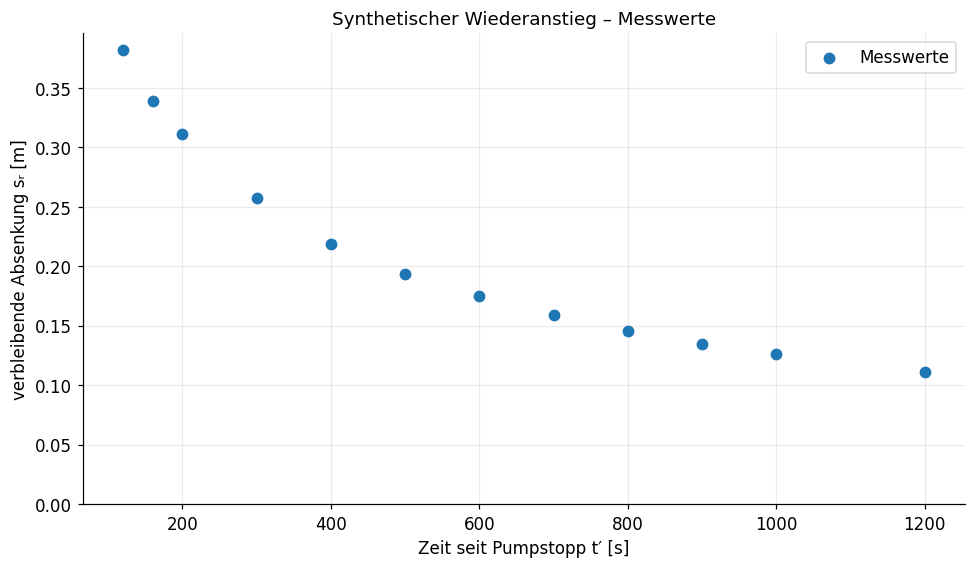

In [3]:
plot_linear(t_prime_syn, s_measured_syn, labels['lin_syn_title'])

### 3.2 Geradlinien-Auswertung – halblogarithmisch

Für die Wiederanstiegsauswertung tragen wir die **verbleibende Absenkung sᵣ** linear gegen das **Zeitverhältnis t/t′** (logarithmische Achse) auf. Die Regression liefert die Steigung **m** und damit **T**. Gezeigt werden nur die synthetischen Messwerte und die Ausgleichsgerade.

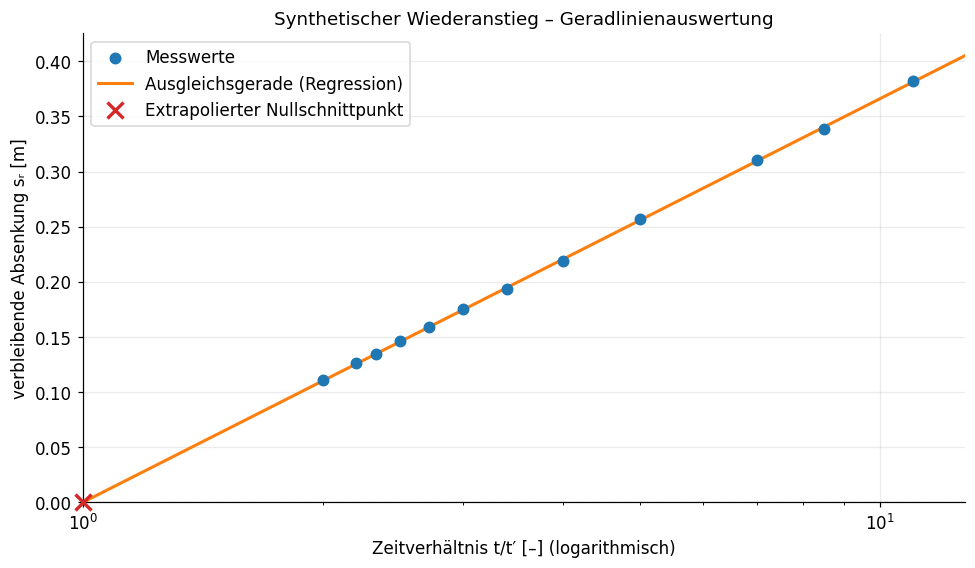

Synthetischer Wiederanstiegsversuch
  Steigung m = 0.36649 m/decade
  Achsenabschnitt b = -0.00018 m
  Transmissivität T = 9.99939e-04 m²/s
  RMSE = 0.00104 m
  Nullschnittpunkt bei t/t′ = 1.001
  Abweichung gegenüber Vorgabe = -0.01 %


In [4]:
fit_syn = recovery_straight_line(t_prime_syn, t_p_syn, Q_syn, s_measured_syn)
plot_recovery_fit(t_prime_syn, s_measured_syn, fit_syn, labels['fittitle_syn'])
print_results(labels['synthetic'], fit_syn)
print(f"  {labels['reldiff']} = "
      f"{100 * (fit_syn['transmissivity'] / T_syn - 1):+.2f} %")

### 3.3 Einordnung

Für die synthetischen Daten kann die berechnete Transmissivität mit der vorgegebenen Transmissivität verglichen werden. Bei realen Pumpversuchen sollten vor allem hinreichend späte Wiederanstiegsdaten ausgewertet werden: Ein kleiner RMSE allein beweist nicht, dass die Voraussetzungen der Näherung erfüllt sind.

## 4. Übungsaufgabe – Wiederanstiegsmessungen

Wir verwenden die **16 Messwerte aus der Übungsaufgabe**. Die Entnahmerate beträgt **Q = 26,7 L/s**; die Messstelle liegt **r = 27,4 m** vom Entnahmebrunnen entfernt. Aus den Zeitangaben ergibt sich eine konstante Pumpdauer von **tₚ = 14.600 s**.

Gesucht ist die **Transmissivität T** mithilfe der geradlinigen Wiederanstiegsauswertung.

In [5]:
# Messdaten der Übungsaufgabe
Q_ex = 0.0267  # m³/s
r_ex = 27.4    # m (information; not required for the straight-line recovery formula)

t_ex = np.array([14765, 14823, 14871, 14920, 15235, 15332, 15600, 15810, 16180, 16400, 17300, 17900, 18560, 19220, 20700, 23300], dtype=float)       # s seit Pumpbeginn
t_prime_ex = np.array([165, 223, 271, 320, 635, 732, 1000, 1210, 1580, 1800, 2700, 3300, 3960, 4620, 6100, 8700], dtype=float)  # s seit Pumpstopp
s_measured_ex = np.array([1.03, 0.95, 0.9, 0.85, 0.69, 0.65, 0.59, 0.55, 0.47, 0.44, 0.35, 0.3, 0.26, 0.23, 0.17, 0.09], dtype=float)  # m

pumping_durations = t_ex - t_prime_ex
if np.any(pumping_durations <= 0) or not np.allclose(pumping_durations, pumping_durations[0]):
    raise ValueError(labels['consistency'])
t_p_ex = float(pumping_durations[0])
print(f"{labels['duration']} = {t_p_ex:.0f} s")
print(f"{labels['exercise']}: {len(t_prime_ex)} {labels['observations']}")
print(labels['help'])


Aus den Zeitangaben ermittelte Pumpdauer tₚ = 14600 s
Übungsaufgabe: 16 Messpunkte
Die verwendeten Messwerte sind verbleibende Absenkungen, nicht der Betrag des Wasserstandsanstiegs.


### 4.1 Messwerte – lineare Darstellung

Die beobachteten Werte der **verbleibenden Absenkung** werden gegen die seit dem Pumpstopp verstrichene Zeit **t′** aufgetragen.

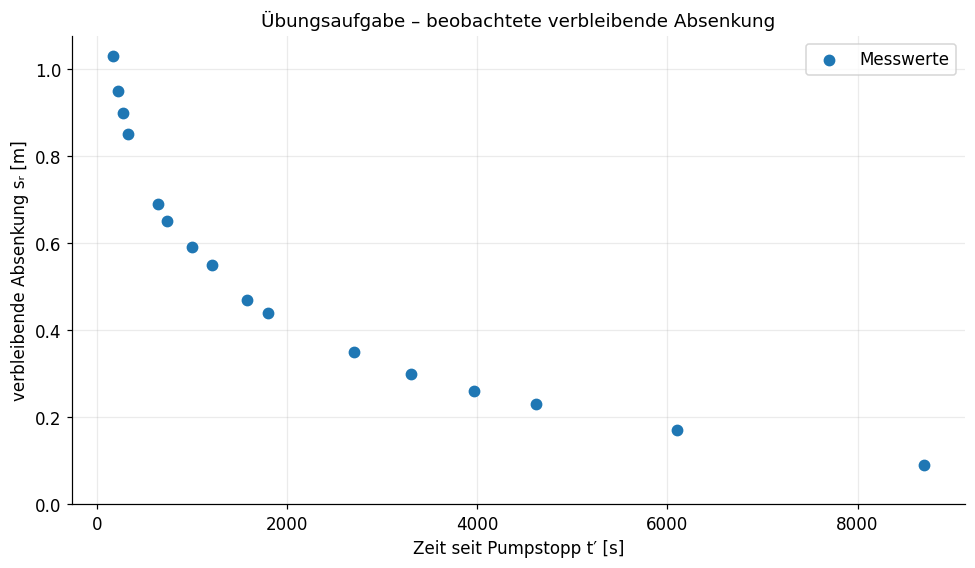

In [6]:
plot_linear(t_prime_ex, s_measured_ex, labels['lin_real_title'])

### 4.2 Wiederanstiegsgerade – halblogarithmische Darstellung

Die x-Achse zeigt das **Zeitverhältnis t/t′** logarithmisch und beginnt bei **10⁰ = 1**. Die y-Achse stellt die **verbleibende Absenkung sᵣ** linear dar und beginnt bei **0 m**. Eine Ausgleichsgerade wird durch die Messwerte gelegt; aus ihrer Steigung berechnen wir **T**. Der extrapolierte Schnittpunkt mit **sᵣ = 0** wird zur Orientierung markiert und ist **kein Reichweitenparameter**.

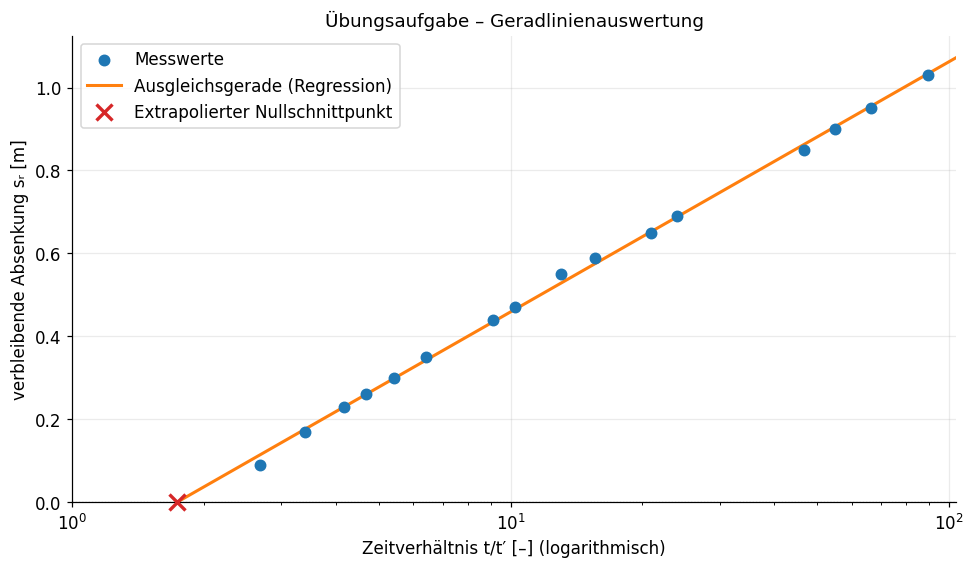

Übungsaufgabe
  Steigung m = 0.60331 m/decade
  Achsenabschnitt b = -0.14442 m
  Transmissivität T = 8.10917e-03 m²/s
  RMSE = 0.00996 m
  Nullschnittpunkt bei t/t′ = 1.735


In [7]:
fit_ex = recovery_straight_line(t_prime_ex, t_p_ex, Q_ex, s_measured_ex)
plot_recovery_fit(t_prime_ex, s_measured_ex, fit_ex, labels['fittitle_real'])
print_results(labels['exercise'], fit_ex)


### 4.3 Anpassungskontrolle

Die Residuen sind **Messwert minus Regressionswert**. Systematische Muster können auf Abweichungen von der Geradlinienannahme hinweisen. Zum Vergleich wird in der Übungsaufgabe eine manuell bestimmte Steigung von etwa **0,58 m pro Dekade** angegeben; die Regression liefert etwa **0,603 m pro Dekade**. Da **T umgekehrt proportional zur Steigung** ist, führt die größere Steigung zu einer **kleineren Transmissivität** (Regression ca. **8,11 · 10⁻³ m²/s**, manuelle Steigung ca. **8,44 · 10⁻³ m²/s**).

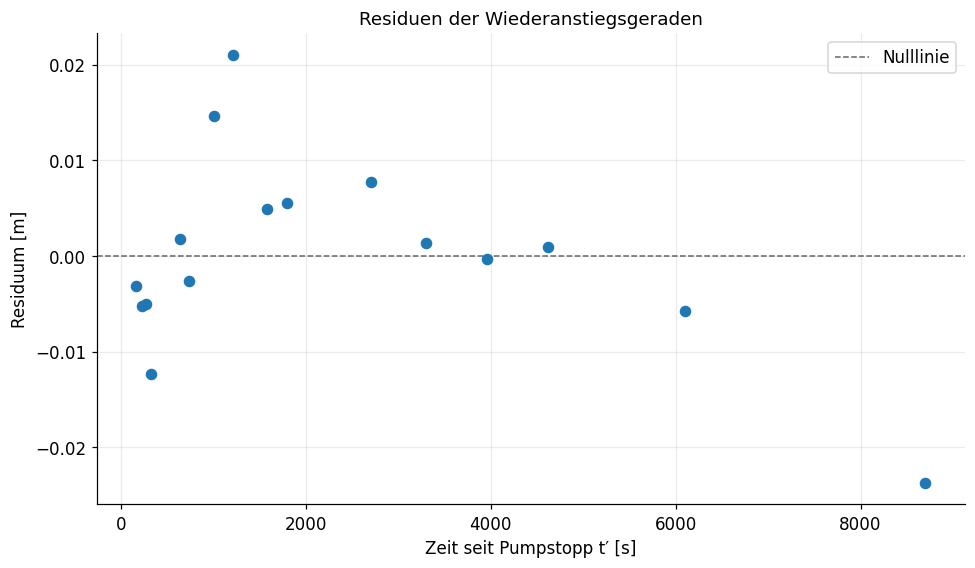

In [8]:
residuals = s_measured_ex - fit_ex['s_fit']
fig, ax = plt.subplots()
ax.scatter(t_prime_ex, residuals, s=43, color='C0', zorder=3)
ax.axhline(0, ls='--', lw=1, color='0.4', label=labels['linezero'])
ax.set(xlabel=labels['time'], ylabel=labels['restxt'], title=labels['restitle'])
ax.legend()
plt.tight_layout()
plt.show()


### 4.4 Kontrolle mit `numpy.linalg.lstsq`

Zur Kontrolle bestimmen wir die Ausgleichsgerade unabhängig mit einem linearen Kleinste-Quadrate-Verfahren. Beide Berechnungen müssen dieselbe Steigung, Transmissivität und denselben RMSE ergeben.

In [9]:
A = np.column_stack([fit_ex['log_ratio'], np.ones_like(fit_ex['log_ratio'])])
(slope_check, intercept_check), *_ = np.linalg.lstsq(A, s_measured_ex, rcond=None)
T_check = Q_ex * np.log(10) / (4 * np.pi * slope_check)
rmse_check = np.sqrt(np.mean((s_measured_ex - A @ [slope_check, intercept_check])**2))

print(labels['crosscheck'])
print(f"  {labels['slope']} = {slope_check:.5f} m/decade")
print(f"  {labels['axis']} = {intercept_check:.5f} m")
print(f"  {labels['trans']} = {T_check:.5e} m²/s")
print(f"  {labels['rmse']} = {rmse_check:.5f} m")
print(f"  {labels['difference']} = {T_check - fit_ex['transmissivity']:+.2e} m²/s")
assert np.isclose(T_check, fit_ex['transmissivity'], rtol=1e-12)
assert np.isclose(rmse_check, fit_ex['rmse'], rtol=1e-12)


Kontrolle mit numpy.linalg.lstsq
  Steigung m = 0.60331 m/decade
  Achsenabschnitt b = -0.14442 m
  Transmissivität T = 8.10917e-03 m²/s
  RMSE = 0.00996 m
  Unterschied in T gegenüber numpy.polyfit = +3.47e-18 m²/s


## 5. Zusammenfassung und Grenzen

| Schritt | Darstellung / Berechnung | Zweck |
|:--|:--|:--|
| Verbleibende Absenkung | **t′** und **sᵣ** linear | Messdaten prüfen |
| Wiederanstiegsauswertung | **t/t′** logarithmisch, **sᵣ** linear | **T** aus der Geradensteigung bestimmen |
| Residuen | linear | Qualität der Anpassung beurteilen |

**Anwendungshinweise:**

- **t** bezeichnet die Zeit **seit Pumpbeginn**, nicht nur die Pumpdauer: **t = tₚ + t′**.
- Die klassische Wiederanstiegsgerade setzt eine **konstante Förderrate** vor dem Pumpstopp und geeignete Wiederanstiegszeiten voraus.
- Brunnenpeicherung, Hintergrundtrends, Aquifergrenzen und Leakage können die Annahmen verletzen.
- Aus der Geradlinienauswertung ist **S** nicht separat bestimmbar.
- Die Zeit- und Absenkungswerte der Übungsaufgabe können durch eigene Messdaten ersetzt werden.

## 6. Literatur

- **Theis, C. V. (1935):** The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage. *Transactions, American Geophysical Union*, 16, 519–524. [DOI](https://doi.org/10.1029/TR016i002p00519).
- **Kruseman, G. P. & de Ridder, N. A. (1990; Nachdruck 1991):** *Analysis and Evaluation of Pumping Test Data*. 2. Auflage, ILRI Publication 47, Wageningen. [The Groundwater Project](https://gw-project.org/books/analysis-and-evaluation-of-pumping-test-data/), insbesondere Kapitel 13.
- **Freeze, R. A. & Cherry, J. A. (1979):** *Groundwater*. Prentice-Hall. [The Groundwater Project](https://gw-project.org/books/groundwater/).
- **USGS:** *The Recovery Method for Determining the Coefficient of Transmissibility*. [Originalbericht (PDF)](https://pubs.usgs.gov/wsp/1536i/report.pdf).

**Hinweis zur Herkunft des Codes:** Die grundlegenden Programmierbeispiele wurden ursprünglich teilweise durch ein [Beispiel von Christian Hill](https://scipython.com/blog/linear-and-non-linear-fitting-of-the-theis-equation) angeregt. Für dieses Notebook wurden Theorie, Auswertung und Darstellung eigenständig didaktisch aufbereitet.